# Etapa 5 — Análisis del experimento: ¿cambia la temperatura el recall y la precisión?

**Diseño.** Red de hipertrofia cardíaca (225 genes, 12 llamadas por réplica), modelo `deepseek-flash` (DeepSeek V4.1 Flash) con el razonamiento desactivado.
Prompt idéntico al del repo de Saucerman Lab (licencia MIT; paper eLife 109709). **Temperatura 1.0** (línea base = la del paper y el valor por defecto de la API): 10 réplicas.
**Temperatura 0**: 3 réplicas.

**Métricas** (mismas funciones que el repo, copiadas en `evaluacion.py`):
recall = TP / (TP + FN); precisión = TP / (TP + FP). Una flecha es acierto solo si coinciden origen, destino **y signo** (activa/inhibe).

In [1]:
import sys
sys.dont_write_bytecode = True
import json, itertools
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy import stats
from pathlib import Path
import evaluacion as ev

RED = "hypertrophy"
RES = ev.RAIZ / "experimento" / "resultados"
DS = RES / "deepseek"
FIG = RES / "figuras"; FIG.mkdir(exist_ok=True)

reps = []
for tdir in sorted(DS.glob("T*")):
    for rdir in sorted(tdir.glob("rep*")):
        if (rdir / "replica.json").exists():
            reps.append({"temp": float(tdir.name[1:]), "rep": int(rdir.name[3:]), "dir": rdir})
print("Réplicas completas encontradas:", {t: sum(1 for r in reps if r['temp'] == t) for t in sorted({r['temp'] for r in reps})})

Réplicas completas encontradas: {0.0: 3, 1.0: 10}


## 1. Calidad de las respuestas

Cada respuesta de la API se clasifica como: `ok`; `vacia` (JSON válido pero 0 interacciones); `sin_contenido` (la API devolvió texto vacío);
`cortada` (la respuesta llegó al tope de 4000 tokens de salida y el JSON quedó incompleto); `malformada` (JSON inválido por otra causa); `rechazada` (rechazo del modelo o error 400).
Las que fallan se reintentan (hasta 3 intentos por llamada) y **todos los intentos se cuentan**. Si la causa fue el corte por longitud, el reintento usa un tope de 16 000 tokens
(desviación del protocolo del paper, que usa 4000, necesaria porque a temperatura 0 las listas salen más largas).

In [2]:
filas = []
for r in reps:
    for f in sorted(r["dir"].glob("llamada_*.json")):
        d = json.loads(f.read_text(encoding="utf-8"))
        estados = [x["estado"] for x in d.get("intentos_previos", [])] + [d["estado"]]
        filas.append({"temperatura": r["temp"], "replica": r["rep"], "llamada": d["llamada"],
                      "n_intentos": len(estados), "estados": estados,
                      "incidencias_api": len(d.get("incidencias_api", [])),
                      "descartadas": d.get("n_descartadas", 0), "forma_alternativa": bool(d.get("normalizada")),
                      "uso_tope_mayor": any(x.get("max_tokens", 4000) > 4000 for x in d.get("intentos_previos", [])) or d.get("max_tokens_usado", 4000) > 4000,
                      "razonamiento": bool(d.get("hubo_razonamiento")),
                      "tokens": (d.get("usage") or {}).get("total_tokens", 0),
                      "tokens_entrada": (d.get("usage") or {}).get("prompt_tokens", 0),
                      "tokens_salida": (d.get("usage") or {}).get("completion_tokens", 0)})
llam = pd.DataFrame(filas)
resp = llam.explode("estados")
calidad = resp.groupby("temperatura").agg(
    respuestas_totales=("estados", "size"),
    ok=("estados", lambda s: (s == "ok").sum()),
    vacias_0_interacciones=("estados", lambda s: (s == "vacia").sum()),
    sin_contenido=("estados", lambda s: (s == "sin_contenido").sum()),
    cortadas_por_limite_de_tokens=("estados", lambda s: (s == "cortada").sum()),
    malformadas_otras=("estados", lambda s: (s == "malformada").sum()),
    rechazadas=("estados", lambda s: (s == "rechazada").sum()))
extra = llam.groupby("temperatura").agg(
    llamadas=("llamada", "size"), reintentos=("n_intentos", lambda s: (s - 1).sum()),
    incidencias_api_429_5xx=("incidencias_api", "sum"), interacciones_descartadas=("descartadas", "sum"),
    forma_alternativa=("forma_alternativa", "sum"), llamadas_que_necesitaron_16000_tokens=("uso_tope_mayor", "sum"),
    con_razonamiento=("razonamiento", "sum"), tokens_entrada=("tokens_entrada", "sum"), tokens_salida=("tokens_salida", "sum"))
calidad = calidad.join(extra)
calidad.loc["total"] = calidad.sum()
calidad.to_csv(RES / "calidad_respuestas.csv", encoding="utf-8")
calidad

,respuestas_totales,ok,vacias_0_interacciones,sin_contenido,cortadas_por_limite_de_tokens,malformadas_otras,rechazadas,llamadas,reintentos,incidencias_api_429_5xx,interacciones_descartadas,forma_alternativa,llamadas_que_necesitaron_16000_tokens,con_razonamiento,tokens_entrada,tokens_salida
temperatura,,,,,,,,,,,,,,,,
0.0,40,36,0,0,4,0,0,36,4,0,0,0,4,0,656250,88529
1.0,120,120,0,0,0,0,0,120,0,0,0,0,0,0,984734,128833
total,160,156,0,0,4,0,0,156,4,0,0,0,4,0,1640984,217362


## 2. Recall y precisión por réplica

Se usan las matrices nodo × nodo del repo. Como verificación cruzada, el número de verdaderos positivos también se calcula con `compare_connections` del repo (una tabla por archivo JSON); deben coincidir.

In [3]:
gt, vacia = ev.matriz_verdad(RED)
verdad = {(s, t, int(gt.loc[s, t])) for s in gt.index for t in gt.columns if gt.loc[s, t] != 0}
idx, cols = list(gt.index), list(gt.columns)

filas, flechas_por_rep, crudas = [], {}, {}
for r in reps:
    datos = json.loads((r["dir"] / "replica.json").read_text(encoding="utf-8"))["interactions"]
    df = pd.DataFrame(datos)
    pm = ev.matriz_prediccion(df, RED, vacia)
    m = ev.metricas(pm, gt)
    tabla = ev.tabla_aciertos_archivo(r["dir"] / "replica.json", RED)
    tp_tabla = int(tabla.drop_duplicates(subset=["source", "target", "action"])["predicted"].sum())
    flechas = {(idx[i], cols[j], int(pm.values[i, j])) for i, j in np.argwhere(pm.values != 0)}
    flechas_por_rep[(r["temp"], r["rep"])] = flechas
    crudas[(r["temp"], r["rep"])] = {(str(x["source_node"]).strip().lower(), str(x["target_node"]).strip().lower(), x["action"]) for x in datos}
    filas.append({"temperatura": r["temp"], "replica": r["rep"], "interacciones_crudas": len(datos),
                  "flechas_unicas_en_modelo": len(flechas), **m, "TP_compare_connections": tp_tabla,
                  "TP_coincide": tp_tabla == m["TP"]})
por_rep = pd.DataFrame(filas)
por_rep.to_csv(RES / "experimento_metricas_por_replica.csv", index=False, encoding="utf-8")
dif_tp = (por_rep["TP_compare_connections"] - por_rep["TP"]).abs()
print(f"TP de las matrices vs TP de compare_connections: coinciden en {int(por_rep['TP_coincide'].sum())} de {len(por_rep)} réplicas; diferencia máxima = {int(dif_tp.max())} TP.")
print("(La única diferencia: si el modelo propone el MISMO par con los dos signos, la matriz conserva el último y la tabla cuenta ambos. Usamos la matriz, que es la métrica formal del paper.)")
print("Flechas en la red hecha a mano (celdas distintas de 0):", len(verdad))
por_rep[["temperatura", "replica", "interacciones_crudas", "flechas_unicas_en_modelo", "TP", "FP", "FN", "recall", "precision", "F1", "signo_contrario"]].round(3)

TP de las matrices vs TP de compare_connections: coinciden en 12 de 13 réplicas; diferencia máxima = 1 TP.
(La única diferencia: si el modelo propone el MISMO par con los dos signos, la matriz conserva el último y la tabla cuenta ambos. Usamos la matriz, que es la métrica formal del paper.)
Flechas en la red hecha a mano (celdas distintas de 0): 191


,temperatura,replica,interacciones_crudas,flechas_unicas_en_modelo,TP,FP,FN,recall,precision,F1,signo_contrario
0,0.0,1,1123,383,99,284,91,0.521,0.258,0.346,1
1,0.0,2,1269,279,97,182,92,0.513,0.348,0.415,2
2,0.0,3,903,200,93,107,97,0.489,0.465,0.477,1
3,1.0,1,563,178,85,93,105,0.447,0.478,0.462,1
4,1.0,2,407,149,77,72,113,0.405,0.517,0.454,1
5,1.0,3,373,159,77,82,111,0.410,0.484,0.444,3
6,1.0,4,534,248,82,166,108,0.432,0.331,0.374,1
7,1.0,5,462,186,88,98,102,0.463,0.473,0.468,1
8,1.0,6,301,169,83,86,107,0.437,0.491,0.462,1
9,1.0,7,679,264,100,164,90,0.526,0.379,0.441,1


## 3. Promedio y desviación estándar por temperatura

In [4]:
sd = lambda s: s.std(ddof=1)
resumen = por_rep.groupby("temperatura").agg(
    n_replicas=("replica", "count"),
    recall_media=("recall", "mean"), recall_sd=("recall", sd),
    precision_media=("precision", "mean"), precision_sd=("precision", sd),
    F1_media=("F1", "mean"), F1_sd=("F1", sd),
    TP_media=("TP", "mean"), FP_media=("FP", "mean"), FN_media=("FN", "mean"),
    flechas_propuestas_media=("flechas_unicas_en_modelo", "mean"))
resumen.to_csv(RES / "experimento_resumen_por_temperatura.csv", encoding="utf-8")
display(resumen.round(3))

a, b = por_rep[por_rep.temperatura == 1.0], por_rep[por_rep.temperatura == 0.0]
comparacion = []
for met in ["recall", "precision", "F1"]:
    t, p = stats.ttest_ind(a[met], b[met], equal_var=False)
    comparacion.append({"metrica": met, "media_T1.0": a[met].mean(), "media_T0": b[met].mean(),
                        "diferencia(T0 - T1.0)": b[met].mean() - a[met].mean(), "t_Welch": t, "p_valor": p})
comparacion = pd.DataFrame(comparacion)
comparacion.to_csv(RES / "experimento_comparacion_temperaturas.csv", index=False, encoding="utf-8")
print("Prueba t de Welch (EXPLORATORIA: solo 3 réplicas a temperatura 0):")
comparacion.round(4)

,n_replicas,recall_media,recall_sd,precision_media,precision_sd,F1_media,F1_sd,TP_media,FP_media,FN_media,flechas_propuestas_media
temperatura,,,,,,,,,,,
0.0,3,0.508,0.016,0.357,0.104,0.412,0.066,96.333,191.0,93.333,287.333
1.0,10,0.445,0.034,0.454,0.059,0.446,0.028,84.300,105.6,105.200,189.900


Prueba t de Welch (EXPLORATORIA: solo 3 réplicas a temperatura 0):


,metrica,media_T1.0,media_T0,diferencia(T0 - T1.0),t_Welch,p_valor
0,recall,0.4448,0.5079,0.0631,-4.4285,0.0026
1,precision,0.4539,0.3571,-0.0969,1.5468,0.2413
2,F1,0.4460,0.4123,-0.0337,0.8654,0.4703


## 4. ¿En cuántas réplicas aparece cada flecha?

Se cuentan las flechas **únicas** (origen, destino, signo), ya traducidas a los nodos del modelo hecho a mano. Se marca si la flecha existe en esa red (verdadera) o no.
Las flechas verdaderas que ninguna réplica propuso aparecen con 0.

In [5]:
def frecuencias(temp):
    claves = [k for k in flechas_por_rep if k[0] == temp]
    n = len(claves)
    cuenta = {}
    for k in claves:
        for f in flechas_por_rep[k]:
            cuenta[f] = cuenta.get(f, 0) + 1
    for f in verdad:
        cuenta.setdefault(f, 0)
    df = pd.DataFrame([{"origen": f[0], "destino": f[1], "signo": "estimulación" if f[2] == 1 else "inhibición",
                        "replicas_en_que_aparece": c, "de_total": n, "esta_en_la_red": f in verdad} for f, c in cuenta.items()])
    return df.sort_values(["replicas_en_que_aparece", "esta_en_la_red"], ascending=False).reset_index(drop=True)

frec = {t: frecuencias(t) for t in (1.0, 0.0)}
for t, d in frec.items():
    d.to_csv(RES / f"frecuencia_flechas_T{t:.1f}.csv", index=False, encoding="utf-8")

f1 = frec[1.0]
tabla_f = f1.groupby(["replicas_en_que_aparece", "esta_en_la_red"]).size().unstack(fill_value=0).rename(columns={True: "en_la_red", False: "no_en_la_red"})
tabla_f["total"] = tabla_f.sum(axis=1)
print("Temperatura 1.0 (10 réplicas): número de flechas según en cuántas réplicas aparecen")
display(tabla_f)
todas = f1[f1.replicas_en_que_aparece == 10]
print(f"Aparecen en las 10 réplicas: {len(todas)} flechas ({todas.esta_en_la_red.sum()} están en la red).")
solo1 = f1[f1.replicas_en_que_aparece == 1]
print(f"Aparecen en una sola réplica: {len(solo1)} flechas ({solo1.esta_en_la_red.sum()} están en la red).")

Temperatura 1.0 (10 réplicas): número de flechas según en cuántas réplicas aparecen


esta_en_la_red,no_en_la_red,en_la_red,total
replicas_en_que_aparece,,,
0,0,61,61
1,183,21,204
2,76,6,82
3,36,7,43
4,26,6,32
5,22,8,30
6,13,8,21
7,13,6,19
8,10,14,24


Aparecen en las 10 réplicas: 43 flechas (37 están en la red).
Aparecen en una sola réplica: 204 flechas (21 están en la red).


## 5. Temperatura 0: ¿cuántas réplicas salieron idénticas entre sí?

Se compara cada par de réplicas de dos maneras: (a) la lista de interacciones **tal cual** la devolvió el modelo (mismo contenido y mismo orden) y (b) el **conjunto** de interacciones (sin importar el orden).
Para contraste, se hace lo mismo con las réplicas de temperatura 1.0.

In [6]:
def comparar(temp):
    claves = sorted(k for k in crudas if k[0] == temp)
    filas = []
    for a_, b_ in itertools.combinations(claves, 2):
        A, B = crudas[a_], crudas[b_]
        da = json.loads((ev.RAIZ / "experimento" / "resultados" / "deepseek" / f"T{temp:.1f}" / f"rep{a_[1]:02d}" / "replica.json").read_text(encoding="utf-8"))["interactions"]
        db = json.loads((ev.RAIZ / "experimento" / "resultados" / "deepseek" / f"T{temp:.1f}" / f"rep{b_[1]:02d}" / "replica.json").read_text(encoding="utf-8"))["interactions"]
        filas.append({"par": f"rep{a_[1]:02d}-rep{b_[1]:02d}", "identicas_mismo_orden": da == db,
                      "identicas_como_conjunto": A == B, "jaccard": len(A & B) / len(A | B)})
    return pd.DataFrame(filas)

for t in (0.0, 1.0):
    c = comparar(t)
    print(f"--- Temperatura {t}: {len(c)} pares de réplicas")
    print(f"  pares idénticos (mismo orden): {int(c.identicas_mismo_orden.sum())} de {len(c)}")
    print(f"  pares idénticos como conjunto: {int(c.identicas_como_conjunto.sum())} de {len(c)}")
    print(f"  similitud de Jaccard: media {c.jaccard.mean():.3f} (mín {c.jaccard.min():.3f}, máx {c.jaccard.max():.3f})")
    if t == 0.0:
        display(c.round(4))
    c.to_csv(RES / f"similitud_replicas_T{t:.1f}.csv", index=False, encoding="utf-8")

--- Temperatura 0.0: 3 pares de réplicas
  pares idénticos (mismo orden): 0 de 3
  pares idénticos como conjunto: 0 de 3
  similitud de Jaccard: media 0.451 (mín 0.406, máx 0.490)


,par,identicas_mismo_orden,identicas_como_conjunto,jaccard
0,rep01-rep02,False,False,0.4058
1,rep01-rep03,False,False,0.4575
2,rep02-rep03,False,False,0.4900


--- Temperatura 1.0: 45 pares de réplicas
  pares idénticos (mismo orden): 0 de 45
  pares idénticos como conjunto: 0 de 45
  similitud de Jaccard: media 0.363 (mín 0.251, máx 0.564)


## 5b. Diagnóstico: ¿la temperatura 0 es reproducible incluso en la primera llamada?

La primera llamada de cada réplica recibe **exactamente la misma entrada** (lista de genes + prompt). Si la temperatura 0 fuera determinista, esas respuestas serían idénticas.
También se mide cuánto escribe el modelo por llamada según la temperatura.

In [7]:
def contenido_llamada(temp, rep, k):
    return json.loads((DS / f"T{temp:.1f}" / f"rep{rep:02d}" / f"llamada_{k:02d}.json").read_text(encoding="utf-8"))

diag, por_llamada = [], {}
for t in (0.0, 1.0):
    claves = sorted(r["rep"] for r in reps if r["temp"] == t)
    for k in range(1, 13):
        cs = [contenido_llamada(t, rp, k) for rp in claves]
        conj = [{(x["source_node"].lower(), x["target_node"].lower(), x["action"]) for x in c["interacciones"]} for c in cs]
        por_llamada[(t, k)] = np.mean([len(s) for s in conj])
        if k in (1, 2, 3, 6, 12):
            pares = list(itertools.combinations(range(len(cs)), 2))
            diag.append({"temperatura": t, "llamada": k, "n_interacciones_media": np.mean([len(s) for s in conj]),
                         "pares_con_texto_identico": f"{sum(cs[a]['content'] == cs[b]['content'] for a, b in pares)} de {len(pares)}",
                         "jaccard_medio": np.mean([len(conj[a] & conj[b]) / len(conj[a] | conj[b]) for a, b in pares])})
diag = pd.DataFrame(diag)
diag.to_csv(RES / "diagnostico_llamadas.csv", index=False, encoding="utf-8")
display(diag.round(3))
print("Interacciones medias por llamada (1..12):")
for t in (0.0, 1.0):
    print(f"  T={t:g}:", [round(por_llamada[(t, k)]) for k in range(1, 13)])

,temperatura,llamada,n_interacciones_media,pares_con_texto_identico,jaccard_medio
0,0.0,1,123.667,0 de 3,0.504
1,0.0,2,141.667,0 de 3,0.555
2,0.0,3,129.667,0 de 3,0.228
3,0.0,6,92.000,0 de 3,0.108
4,0.0,12,28.000,0 de 3,0.074
5,1.0,1,53.000,0 de 45,0.322
6,1.0,2,57.800,0 de 45,0.198
7,1.0,3,47.900,0 de 45,0.129
8,1.0,6,39.100,0 de 45,0.061
9,1.0,12,19.300,0 de 45,0.015


Interacciones medias por llamada (1..12):
  T=0: [124, 142, 130, 143, 91, 92, 118, 91, 52, 50, 39, 28]
  T=1: [53, 58, 48, 45, 38, 39, 37, 38, 34, 34, 35, 19]


## 6. Figuras (PNG, etiquetas en español)

Colores: recall = azul, precisión = naranja (misma asignación en las figuras 1 y 3); flechas en la red = aqua, fuera de la red = gris.
Paleta validada con el script del skill de visualización (separación para daltonismo y suelo de visión normal).

In [8]:
SUP, INK, INK2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
AZUL, NARANJA, AQUA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#b3b1a8"
plt.rcParams.update({"figure.facecolor": SUP, "axes.facecolor": SUP, "savefig.facecolor": SUP, "text.color": INK,
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "axes.edgecolor": GRID,
                     "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "Arial", "DejaVu Sans"], "font.size": 11})

def limpiar(ax):
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.spines["left"].set_color(GRID); ax.spines["bottom"].set_color(GRID)
    ax.yaxis.grid(True, color=GRID, lw=0.8); ax.set_axisbelow(True)
    ax.tick_params(length=0)

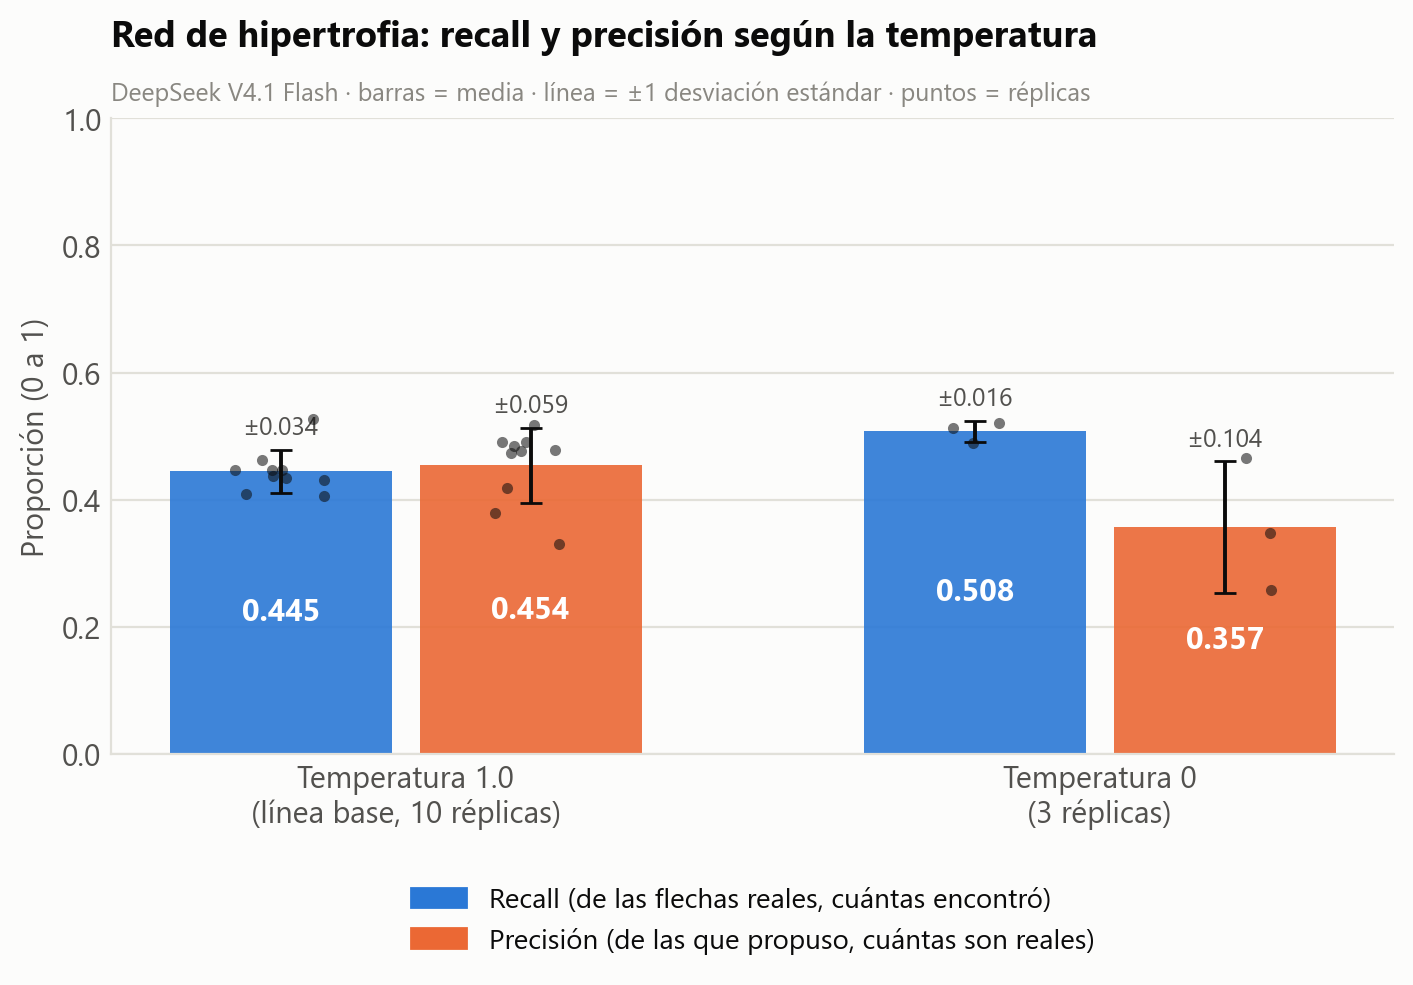

In [9]:
# FIGURA 1: recall y precisión por temperatura
rng = np.random.default_rng(1)
fig, ax = plt.subplots(figsize=(7.2, 5.2), dpi=200)
grupos = [(1.0, "Temperatura 1.0\n(línea base, 10 réplicas)"), (0.0, "Temperatura 0\n(3 réplicas)")]
ancho = 0.32
for gi, (t, etiqueta) in enumerate(grupos):
    d = por_rep[por_rep.temperatura == t]
    for mi, (met, col, nombre) in enumerate([("recall", AZUL, "Recall"), ("precision", NARANJA, "Precisión")]):
        x = gi + (mi - 0.5) * (ancho + 0.04)
        media, desv = d[met].mean(), d[met].std(ddof=1)
        ax.bar(x, media, ancho, color=col, alpha=0.9, zorder=2)
        ax.errorbar(x, media, yerr=desv, color=INK, capsize=4, lw=1.4, zorder=4)
        ax.scatter(x + rng.uniform(-0.07, 0.07, len(d)), d[met], s=16, color=INK, alpha=0.55, zorder=5, linewidths=0)
        ax.text(x, media / 2, f"{media:.3f}", ha="center", va="center", color="white", fontsize=11, fontweight="bold", zorder=6)
        ax.text(x, media + desv + 0.015, f"±{desv:.3f}", ha="center", va="bottom", color=INK2, fontsize=9)
ax.set_xticks([0, 1]); ax.set_xticklabels([g[1] for g in grupos])
ax.set_ylim(0, 1.0); ax.set_ylabel("Proporción (0 a 1)")
ax.legend(handles=[Patch(color=AZUL, label="Recall (de las flechas reales, cuántas encontró)"),
                   Patch(color=NARANJA, label="Precisión (de las que propuso, cuántas son reales)")],
          loc="upper center", bbox_to_anchor=(0.5, -0.17), frameon=False, ncol=1, fontsize=10)
ax.set_title("Red de hipertrofia: recall y precisión según la temperatura", loc="left", fontsize=13, fontweight="bold", pad=26)
ax.text(0, 1.02, "DeepSeek V4.1 Flash · barras = media · línea = ±1 desviación estándar · puntos = réplicas",
        transform=ax.transAxes, fontsize=9, color=MUTED, va="bottom")
limpiar(ax); fig.tight_layout()
fig.savefig(FIG / "fig1_recall_precision_por_temperatura.png"); plt.show()

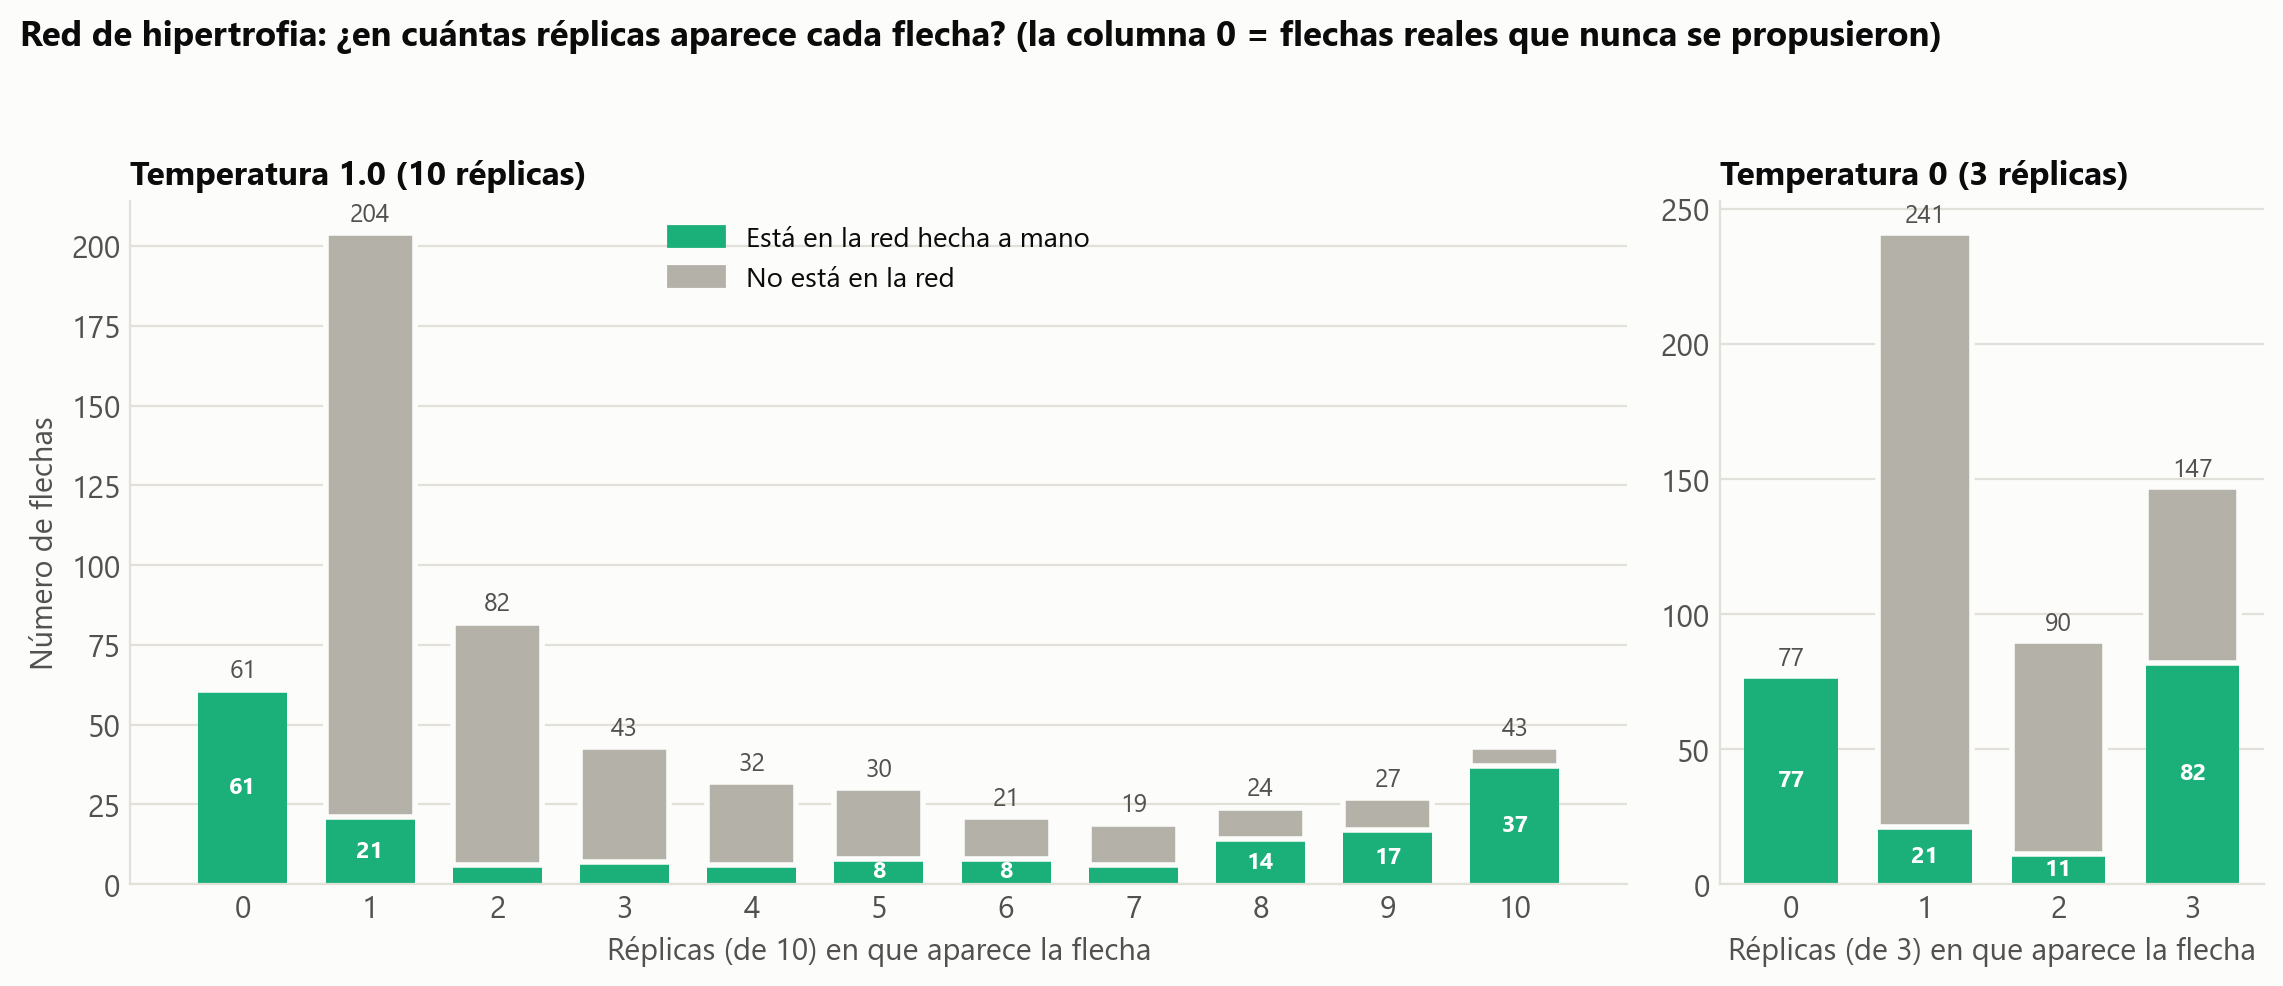

In [10]:
# FIGURA 2: en cuántas réplicas aparece cada flecha
fig, axes = plt.subplots(1, 2, figsize=(11.5, 5), dpi=200, gridspec_kw={"width_ratios": [11, 4]})
for ax, t, n in zip(axes, (1.0, 0.0), (10, 3)):
    d = frec[t]
    c = d.groupby(["replicas_en_que_aparece", "esta_en_la_red"]).size().unstack(fill_value=0).reindex(range(0, n + 1), fill_value=0)
    en, fuera = c.get(True, pd.Series(0, index=c.index)), c.get(False, pd.Series(0, index=c.index))
    x = np.arange(0, n + 1)
    ax.bar(x, en, 0.7, color=AQUA, zorder=2)
    ax.bar(x, fuera, 0.7, bottom=en + 0.0, color=GRIS, zorder=2, edgecolor=SUP, linewidth=2)
    for xi, a_, b_ in zip(x, en, fuera):
        if a_ + b_ > 0:
            ax.text(xi, a_ + b_ + 2, str(int(a_ + b_)), ha="center", va="bottom", fontsize=9, color=INK2)
        if a_ >= 8:
            ax.text(xi, a_ / 2, str(int(a_)), ha="center", va="center", fontsize=8.5, color="white", fontweight="bold")
    ax.set_xticks(x); ax.set_xlabel(f"Réplicas (de {n}) en que aparece la flecha")
    ax.set_title(f"Temperatura {t:.1f}".replace("0.0", "0") + f" ({n} réplicas)", loc="left", fontsize=12, fontweight="bold")
    limpiar(ax)
axes[0].set_ylabel("Número de flechas")
axes[0].legend(handles=[Patch(color=AQUA, label="Está en la red hecha a mano"), Patch(color=GRIS, label="No está en la red")],
               frameon=False, loc="upper center", fontsize=10)
fig.suptitle("Red de hipertrofia: ¿en cuántas réplicas aparece cada flecha? (la columna 0 = flechas reales que nunca se propusieron)",
             x=0.01, ha="left", fontsize=12.5, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(FIG / "fig2_frecuencia_de_flechas.png"); plt.show()

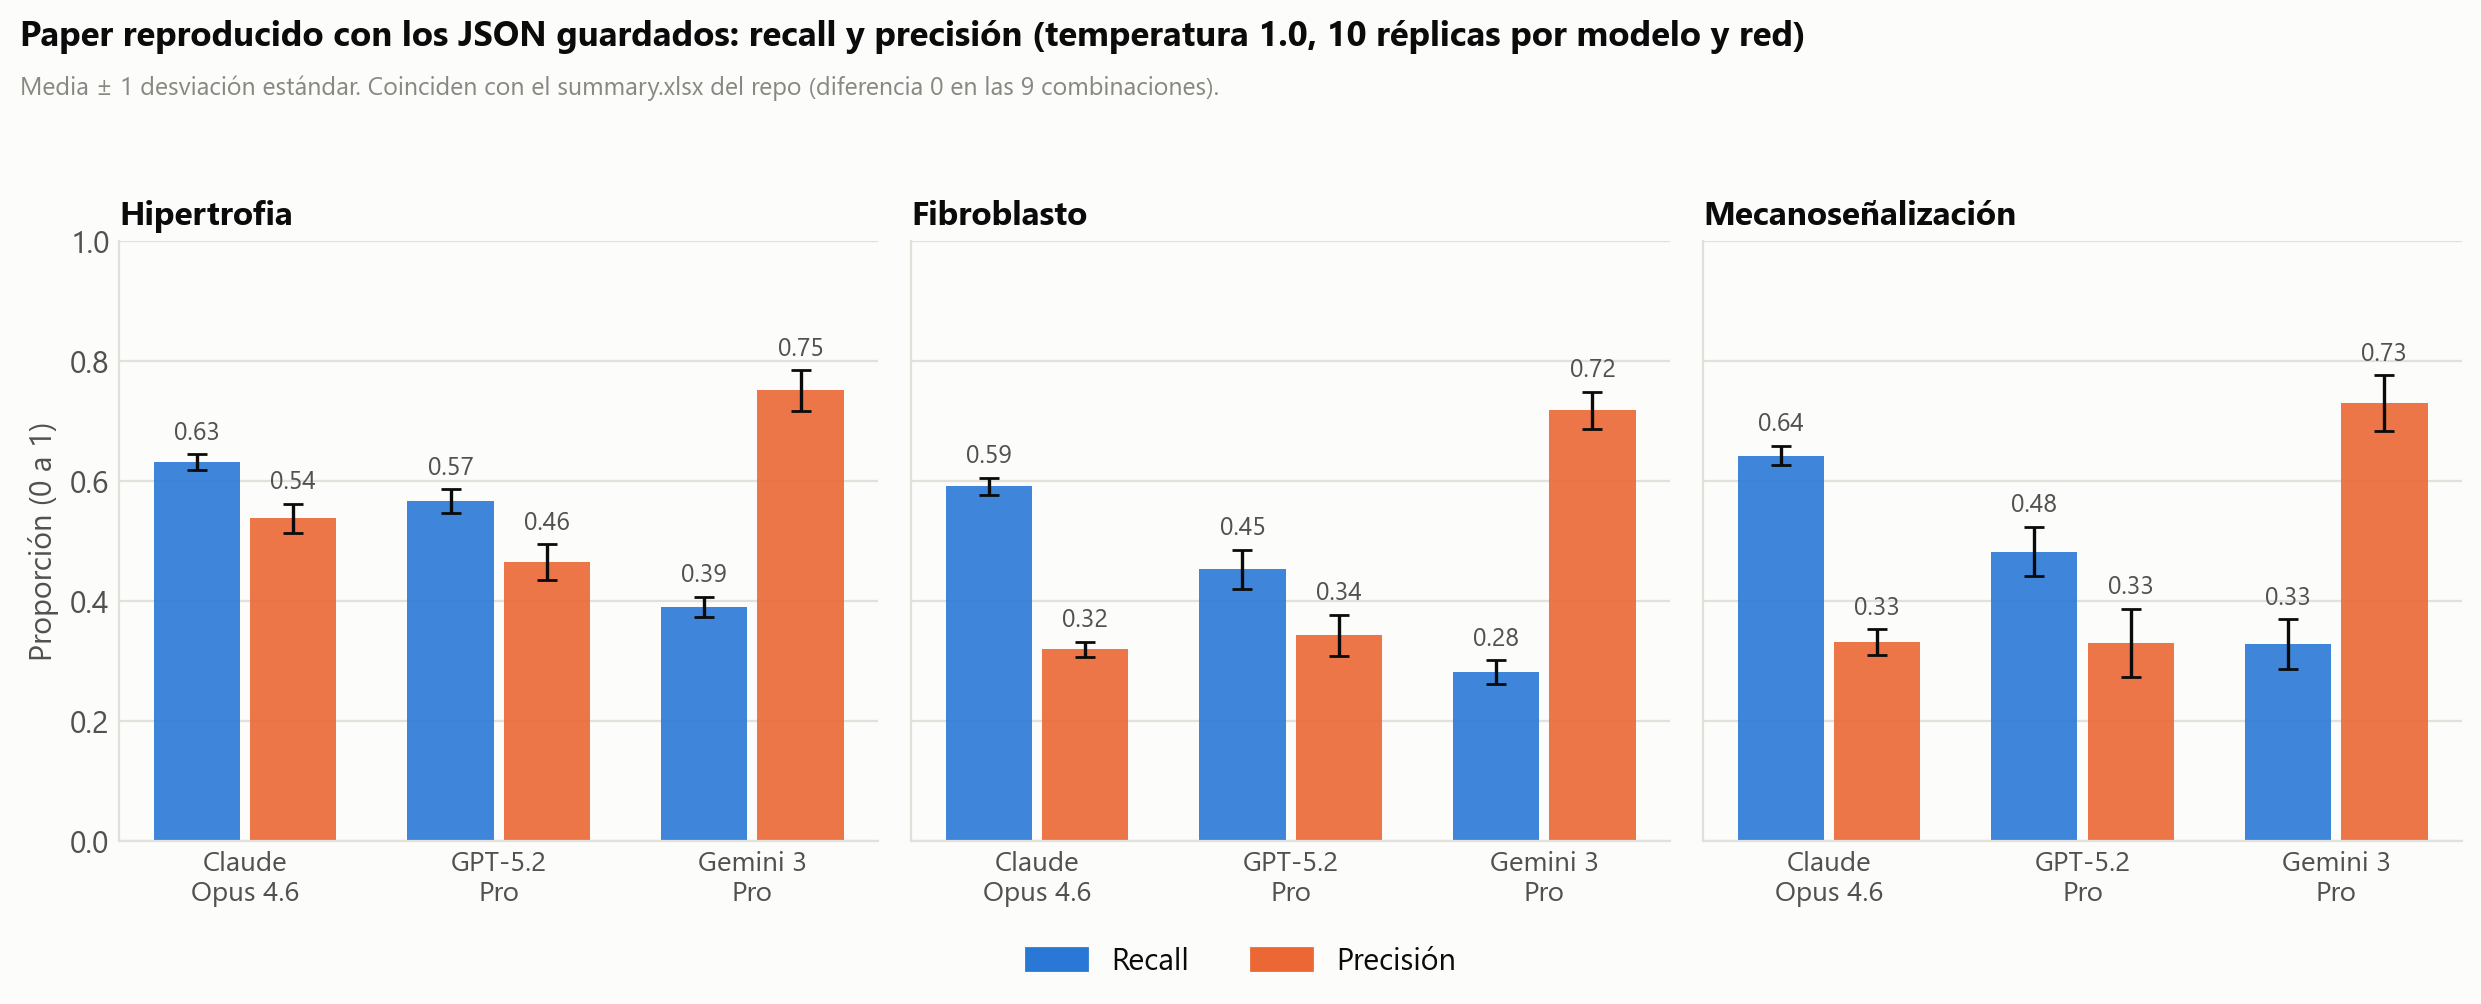

Figuras guardadas en C:\Users\lauta\Desktop\Biologia Computacional\Examen Parcial\Benchmarking biochemical networks\experimento\resultados\figuras


In [11]:
# FIGURA 3: métricas del paper reproducidas en la Etapa 3
rp = pd.read_csv(RES / "reproduccion_paper_resumen.csv")
redes = [("hypertrophy", "Hipertrofia"), ("fibroblast", "Fibroblasto"), ("mechanosignaling", "Mecanoseñalización")]
llms = [("claude", "Claude\nOpus 4.6"), ("gpt", "GPT-5.2\nPro"), ("gemini", "Gemini 3\nPro")]
fig, axes = plt.subplots(1, 3, figsize=(12.5, 5), dpi=200, sharey=True)
for ax, (rk, rn) in zip(axes, redes):
    for li, (lk, ln) in enumerate(llms):
        fila = rp[(rp.red == rk) & (rp.llm == lk)].iloc[0]
        for mi, (col, sdcol, c, off) in enumerate([("recall_media", "recall_sd", AZUL, -0.19), ("precision_media", "precision_sd", NARANJA, 0.19)]):
            ax.bar(li + off, fila[col], 0.34, color=c, alpha=0.9, zorder=2)
            ax.errorbar(li + off, fila[col], yerr=fila[sdcol], color=INK, capsize=3.5, lw=1.2, zorder=4)
            ax.text(li + off, fila[col] + fila[sdcol] + 0.015, f"{fila[col]:.2f}", ha="center", va="bottom", fontsize=9, color=INK2)
    ax.set_xticks(range(3)); ax.set_xticklabels([l[1] for l in llms], fontsize=10)
    ax.set_title(rn, loc="left", fontsize=12, fontweight="bold"); limpiar(ax); ax.set_ylim(0, 1.0)
axes[0].set_ylabel("Proporción (0 a 1)")
fig.legend(handles=[Patch(color=AZUL, label="Recall"), Patch(color=NARANJA, label="Precisión")], loc="lower center", ncol=2, frameon=False, fontsize=11)
fig.suptitle("Paper reproducido con los JSON guardados: recall y precisión (temperatura 1.0, 10 réplicas por modelo y red)",
             x=0.01, ha="left", fontsize=12.5, fontweight="bold")
fig.text(0.01, 0.905, "Media ± 1 desviación estándar. Coinciden con el summary.xlsx del repo (diferencia 0 en las 9 combinaciones).", fontsize=9, color=MUTED)
fig.tight_layout(rect=(0, 0.06, 1, 0.9))
fig.savefig(FIG / "fig3_metricas_del_paper_reproducidas.png"); plt.show()
print("Figuras guardadas en", FIG)